In [1]:
# Imports
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from dyMES.model import model
import dyMES.rfunctions as rf
from sir.sir_scaled import model as sir_model

In [2]:
# Helper code for saving figures
plt.rcParams.update({
    "pdf.fonttype": 42,   # embed fonts as TrueType (journal requires embedded fonts)
    "ps.fonttype": 42,
    "font.size": 8,       # readable at print size
    "axes.labelsize": 8,
    "legend.fontsize": 7,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_fig(fig, name):
    """Save a figure as vector PDF (journal upload) and 1000-dpi PNG (for Word)."""
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=1000, bbox_inches="tight")
    # fig.savefig(FIG_DIR / f"{name}.tiff", dpi=1000, bbox_inches="tight")  # only if bioRxiv wants separate files

# SIR

We can initialize a SIR model by creating an `sir_model` object, which stores all *s*, *n*, *r*, d*s*/d*t*, d*n*/d*t*, and d*r*/d*t* values. To run the model, call `simulate_sir`.

In [3]:
sir_model_obj = sir_model(0.33 / 100, 1/6, 100)
sir_model_obj.simulate_sir(99, 1, 0, 246, 0.0001)

The scaled_sir_vals line below scales the single-group measurements in sir_model_obj by a factor of *G*.

In [4]:
scaled_sir_vals = [i * sir_model_obj.G for i in sir_model_obj.sim_n]

In [5]:
# peak
print("Peak SIR:", max(scaled_sir_vals))
print("Time to peak SIR:", scaled_sir_vals.index(max(scaled_sir_vals))/10000)

Peak SIR: 1551.7807243276911
Time to peak SIR: 26.619


I manually examined scaled_sir_vals to obtain the below:

In [54]:
# time to get to 100
print("SIR time to return to 100:",(int(64.40 * 10000) - 9)/10000)

SIR time to return to 100: 64.3991


In [55]:
scaled_sir_vals[int(64.40 * 10000) - 9]

np.float64(100.00027942130939)

# DyMES infrastructure

In [7]:
def pandemic_func(n, I, params):
    m_effective = (params['m_(t-tau)'] - params['c1'] * params['tau'] * params['d_0'] * n)
    
    return (params['c0'] * params['h'] * n * np.exp(- 1 * (I - 100) / params['K'])) * (m_effective - n) - (params['d_0'] * n)

We can run a pandemic DyMES model with finite or infinite K for a set number of days using the `new_run_model_for_K` method below. The model will run until:
- num_days is reached
- the model reaches 100
- the constraints are no longer being met

The infinite K model is initialized separately due to the handling of the K term when K = inf, but the stopping conditions are the same.

In [ ]:
def new_run_model_for_K(K, new_c0 = 0.006, tau = 0.0001, num_days = 7):
    # Instantiate params
    model_params = {
        'm_0': 100,
        'G': 100,
        'K': K,
        'd_0': 1/6,
        'c0': 0.006,
        'c1': 1,
        'c2': 1,
        'tau': tau,
        '<n>_(t-tau)': 0,
        'm_(t-tau)': 100, # should be set to the same value as m_0
        'h': 1,
    }
    print(model_params)
    initial_infected = 100

    pandemic_dymes = model(initial_infected, model_params, pandemic_func, 'G')

    pandemic_dymes.update_param('c0', pandemic_dymes.find_steady_state_params('c0'))
    print("Steady state c0:", pandemic_dymes.params['c0'])

    pandemic_dymes.update_param('c0', new_c0 / 100)
    print("Updated c0:", pandemic_dymes.params['c0'])
    pandemic_dymes.only_brute_force_update(num_days, dt = tau)

    return pandemic_dymes

In [9]:
from dyMES.model_k_inf import model as model_k_inf

In [10]:
def pandemic_func_K_inf(n, I, params):
    m_effective = (params['m_(t-tau)'] - params['c1'] * params['tau'] * params['d_0'] * n)

    return (params['c0'] * params['h'] * n * np.exp(0)) * (m_effective - n) - (params['d_0'] * n)

In [ ]:
def new_run_model_for_K_inf(new_c0 = 0.006, tau = 0.0001, num_days = 7):
  # Instantiate params
  model_params = {
    'm_0': 100,
    'G': 100,
    # 'K': K,
    'd_0': 1/6,
    'c0': 0.006, 
    'c1': 1,
    'c2': 1,
    'tau': tau,
    '<n>_(t-tau)': 0,
    'm_(t-tau)': 100, # should be set to the same value as m_0
    'h': 1,
  }
  initial_infected = 100

  pandemic_dymes = model_k_inf(initial_infected, model_params, pandemic_func_K_inf, 'G')

  pandemic_dymes.update_param('c0', pandemic_dymes.find_steady_state_params('c0'))
  print("Steady state c0:", pandemic_dymes.params['c0'])

  pandemic_dymes.update_param('c0', new_c0 / 100)
  print("Updated c0:", pandemic_dymes.params['c0'])
  pandemic_dymes.only_brute_force_update(num_days, dt = tau)

  return pandemic_dymes

# Test DyMES

##  K = 100

In [12]:
K_100 = new_run_model_for_K(100, new_c0 = 0.33, num_days = 210)

{'m_0': 100, 'G': 100, 'K': 100, 'd_0': 0.16666666666666666, 'c0': 0.006, 'c1': 1, 'c2': 1, 'tau': 0.0001, '<n>_(t-tau)': 0, 'm_(t-tau)': 100, 'h': 1}
Steady state c0: 0.0017182139440965348
Updated c0: 0.0033


In [13]:
print("Peak state DyMES K = 100:", max(K_100.states),)
print("Time to peak DyMES K = 100:",  np.argmax(K_100.states)/10000)

Peak state DyMES K = 100: 159.8624264053285
Time to peak DyMES K = 100: 15.3965


In [14]:
# time to reach 100, final state, number dead, number susceptible, derivative, and lambdas
print("DyMES K = 100 time to return to 100:", K_100.time[-1])
print("DyMES K = 100 final state:", K_100.states[-1])
print("DyMES K = 100 final m_eff:", K_100.m_effs[-1])
print("DyMES K = 100 final number dead:", K_100.num_dead[-1])
print("DyMES K = 100 final derivative:", K_100.derivatives[-1])
print("DyMES K = 100 final lambda:", K_100.lambdas[-1])

DyMES K = 100 time to return to 100: 185.17780000502373
DyMES K = 100 final state: 99.99997848590613
DyMES K = 100 final m_eff: 58.66883207697609
DyMES K = 100 final number dead: 4133.116792302362
DyMES K = 100 final derivative: -0.2693513064680474
DyMES K = 100 final lambda: [0.71343474 3.65812589]


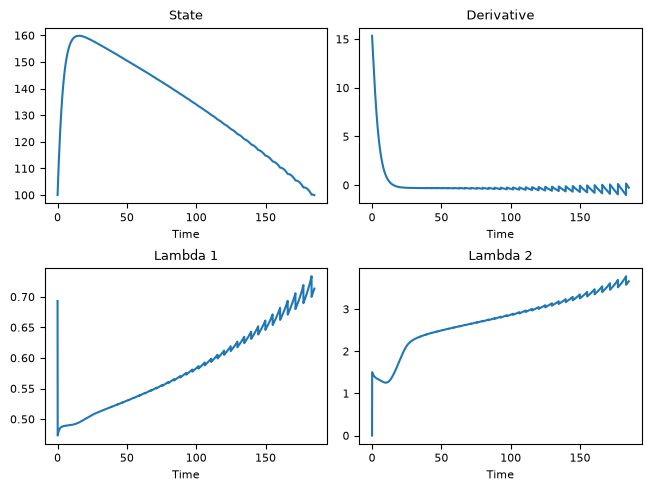

In [15]:
K_100.graph()

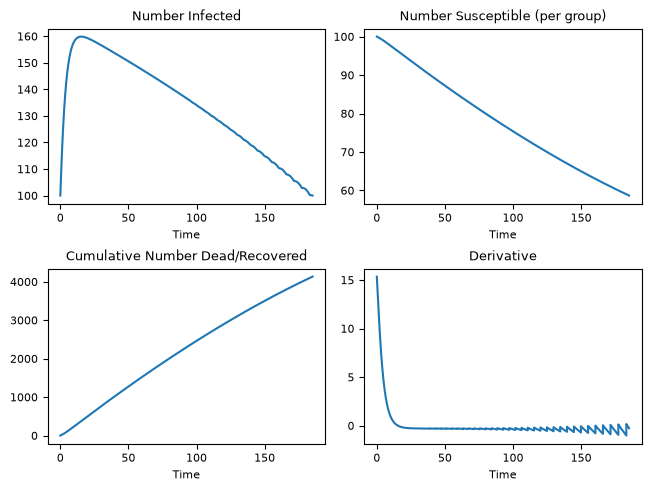

In [16]:
K_100.graph_v2()

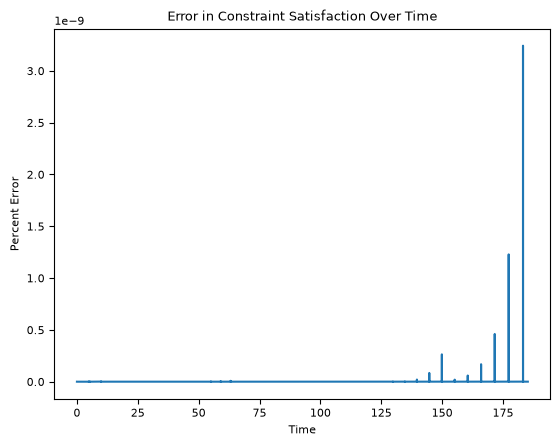

In [17]:
K_100.graph_constraint_errors()

## K = 400

In [18]:
K_400 = new_run_model_for_K(400, new_c0 = 0.33, num_days = 210)

{'m_0': 100, 'G': 100, 'K': 400, 'd_0': 0.16666666666666666, 'c0': 0.006, 'c1': 1, 'c2': 1, 'tau': 0.0001, '<n>_(t-tau)': 0, 'm_(t-tau)': 100, 'h': 1}
Steady state c0: 0.0017182139440965348
Updated c0: 0.0033


In [19]:
print("Peak state DyMES K = 400:", max(K_400.states),)
print("Time to peak DyMES K = 400:",  np.argmax(K_400.states)/10000)

Peak state DyMES K = 400: 252.25335891576887
Time to peak DyMES K = 400: 22.1234


In [20]:
# time to reach 100, final state, number dead, number susceptible, derivative, and lambdas
print("DyMES K = 400 time to return to 100:", K_400.time[-1])
print("DyMES K = 400 final state:", K_400.states[-1])
print("DyMES K = 400 final m_eff:", K_400.m_effs[-1])
print("DyMES K = 400 final number dead:", K_400.num_dead[-1])
print("DyMES K = 400 final derivative:", K_400.derivatives[-1])
print("DyMES K = 400 final lambda:", K_400.lambdas[-1])

DyMES K = 400 time to return to 100: 83.4616000016471
DyMES K = 400 final state: 99.99982790403395
DyMES K = 400 final m_eff: 73.55137460562995
DyMES K = 400 final number dead: 2644.8625394363007
DyMES K = 400 final derivative: -2.3532549482203797
DyMES K = 400 final lambda: [0.72230312 3.94163172]


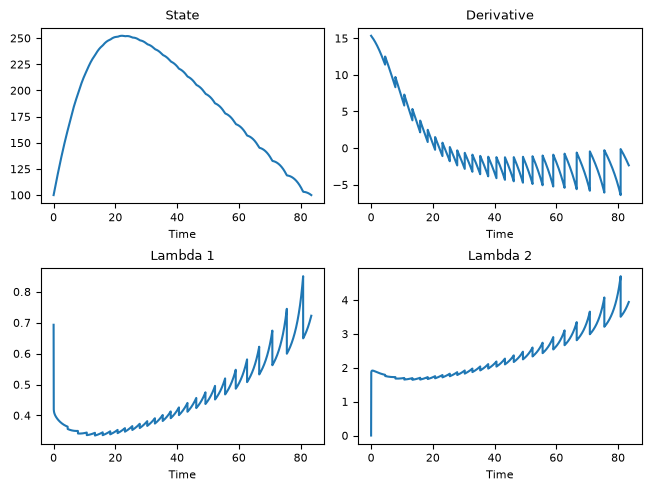

In [21]:
K_400.graph()

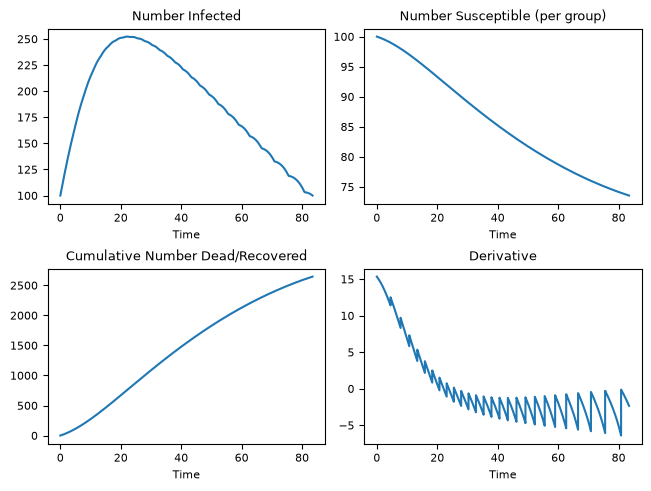

In [22]:
K_400.graph_v2()

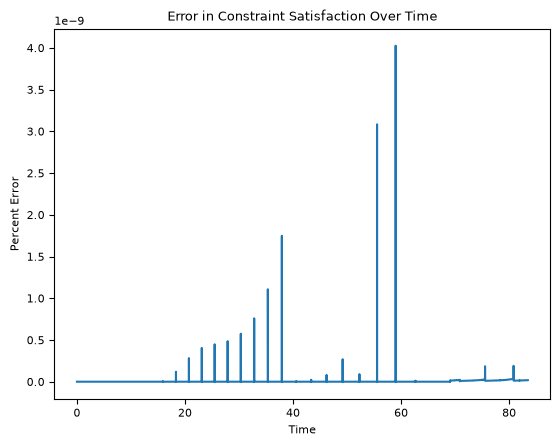

In [23]:
K_400.graph_constraint_errors()

## K = 25

In [24]:
K_25 = new_run_model_for_K(25, new_c0 = 0.33, num_days = 260)

{'m_0': 100, 'G': 100, 'K': 25, 'd_0': 0.16666666666666666, 'c0': 0.006, 'c1': 1, 'c2': 1, 'tau': 0.0001, '<n>_(t-tau)': 0, 'm_(t-tau)': 100, 'h': 1}
Steady state c0: 0.0017182139440965348
Updated c0: 0.0033


In [25]:
print("Peak state DyMES K = 25:", max(K_25.states),)
print("Time to peak DyMES K = 25:",  np.argmax(K_25.states)/10000)

Peak state DyMES K = 25: 115.8892233651064
Time to peak DyMES K = 25: 6.8828


In [26]:
# time to reach 100, final state, number dead, number susceptible, derivative, and lambdas
print("DyMES K = 25 time to return to 100:", K_25.time[-1])
print("DyMES K = 25 final state:", K_25.states[-1])
print("DyMES K = 25 final m_eff:", K_25.m_effs[-1])
print("DyMES K = 25 final number dead:", K_25.num_dead[-1])
print("DyMES K = 25 final derivative:", K_25.derivatives[-1])
print("DyMES K = 25 final lambda:", K_25.lambdas[-1])

DyMES K = 25 time to return to 100: 246.84560000707089
DyMES K = 25 final state: 99.99999153774286
DyMES K = 25 final m_eff: 55.17994547617093
DyMES K = 25 final number dead: 4482.005452382881
DyMES K = 25 final derivative: -0.15373327099889553
DyMES K = 25 final lambda: [0.71931976 3.50043051]


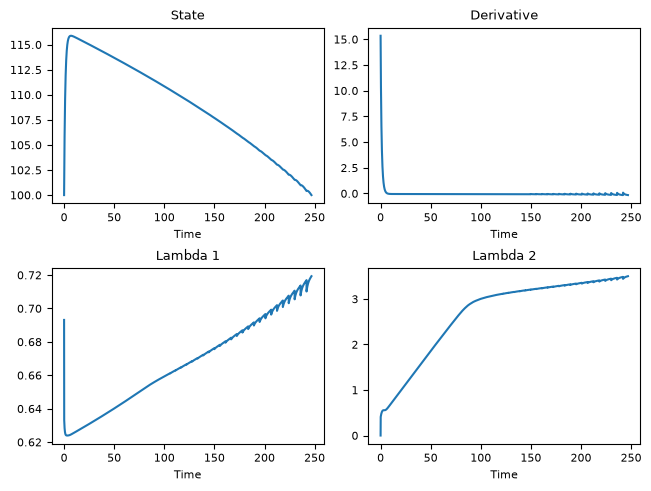

In [27]:
K_25.graph()

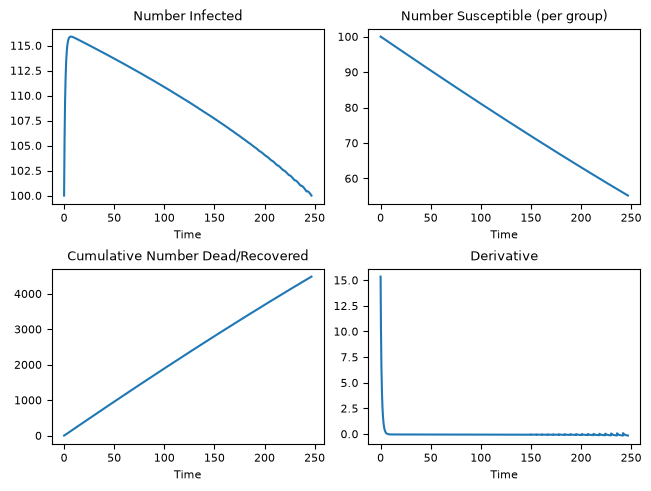

In [28]:
K_25.graph_v2()

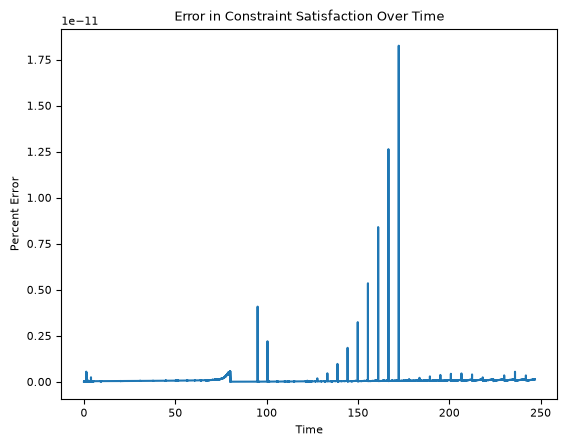

In [29]:
K_25.graph_constraint_errors()

## K = inf

In [30]:
K_inf = new_run_model_for_K_inf(tau = 0.0001, new_c0 = 0.33, num_days = 80)

Steady state c0: 0.0017182139440965348
Updated c0: 0.0033


In [31]:
print("Peak state DyMES K = inf:", max(K_inf.states),)
print("Time to peak DyMES K = inf:",  np.argmax(K_inf.states)/10000)

Peak state DyMES K = inf: 373.99328385047863
Time to peak DyMES K = inf: 27.8177


In [32]:
# time to reach 100, final state, number dead, number susceptible, derivative, and lambdas
print("DyMES K = inf time to return to 100:", K_inf.time[-1])
print("DyMES K = inf final state:", K_inf.states[-1])
print("DyMES K = inf final m_eff:", K_inf.m_effs[-1])
print("DyMES K = inf final number dead:", K_inf.num_dead[-1])
print("DyMES K = inf final derivative:", K_inf.derivatives[-1])
print("DyMES K = inf final lambda:", K_inf.lambdas[-1])

DyMES K = inf time to return to 100: 63.846600000995956
DyMES K = inf final state: 99.99999114752745
DyMES K = inf final m_eff: 72.0202059263248
DyMES K = inf final number dead: 2797.979407367141
DyMES K = inf final derivative: -12.665434726375205
DyMES K = inf final lambda: [1.39918518 8.02559885]


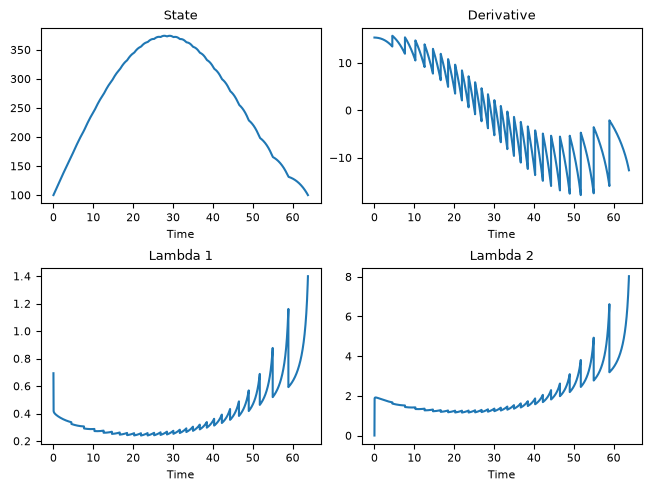

In [33]:
K_inf.graph()

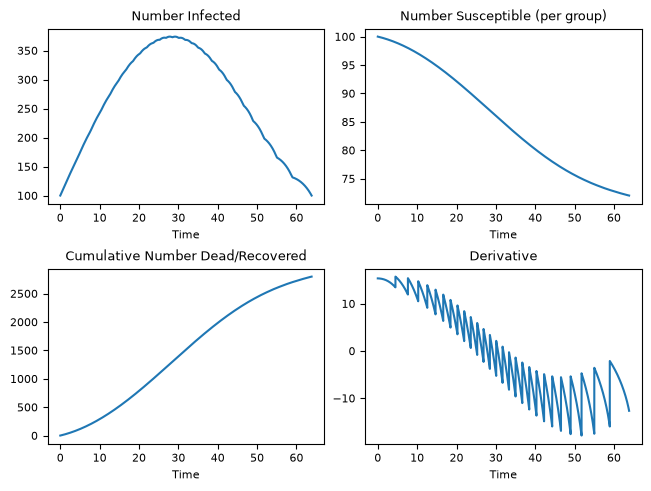

In [34]:
K_inf.graph_v2()

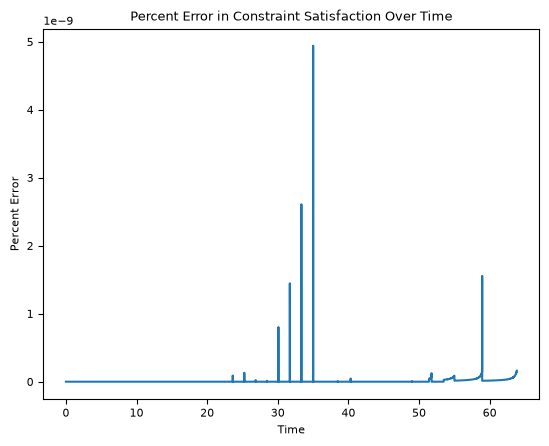

In [35]:
K_inf.graph_constraint_errors()

# Figure Graphs

In [36]:
model_list = [K_25,
                  K_100,
                  K_400,
                  K_inf,]
labels = ["K = 25", "K = 100", "K = 400", "K = inf"]
K_vals = [25, 100, 400]

K_cmap = plt.get_cmap('plasma')
K_norm = plt.Normalize(vmin=0, vmax=len(model_list))

## Figure 1c

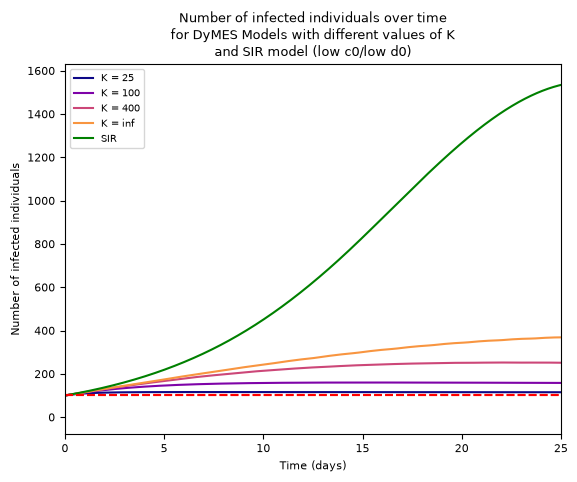

In [37]:
fig, ax = plt.subplots()

for i in range(len(model_list)):
  ax.plot(model_list[i].time,
           model_list[i].states,
           label = labels[i],
           color = K_cmap(K_norm(i))
    )

ax.plot(
    sir_model_obj.t,
    scaled_sir_vals,
    label = "SIR",
    color = 'green',
)

ax.axhline(y=100, color='r', linestyle='--')
ax.axhline(y=100, color='r', linestyle='--')
ax.set_xlim(0, 25)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Number of infected individuals")
ax.set_title("Number of infected individuals over time\nfor DyMES Models with different values of K" \
"\nand SIR model (low c0/low d0)")
ax.legend()

save_fig(fig, 'fig_1c')
plt.show()

##  Figure 2c

In [38]:
log_prob_n_max = 20  # largest n to include; adjust as needed

def nearest_stored_time(dymes_model, target_time):
    """Returns the key in dymes_model.probability_distributions closest to target_time."""
    keys = list(dymes_model.probability_distributions.keys())
    return min(keys, key = lambda k: abs(k - target_time))

def log_prob_curve(dymes_model, time_key, n_max = 10):
    """
    Computes n vs log(P(n)) from a stored probability-distribution snapshot.

    Points where P(n) underflows to exactly 0 (log undefined) are dropped.

    Args:
        dymes_model: a dyMES model object with populated probability_distributions
        time_key: an exact key into dymes_model.probability_distributions
        n_max: largest n to include

    Returns:
        n_vals: array of n values plotted (x-axis)
        log_p_vals: log(P(n)) at each n (y-axis)
        n_mean: <n> of the full distribution at this snapshot (used to build
            the matching geometric curve)
    """
    prob_dist = dymes_model.probability_distributions[time_key]
    normalized_pd = prob_dist / np.sum(prob_dist)

    full_n_array = np.arange(len(normalized_pd))
    n_mean = np.sum(full_n_array * normalized_pd)

    n_vals = np.arange(0, min(n_max, len(normalized_pd) - 1) + 1)
    p_vals = normalized_pd[n_vals]

    valid = p_vals > 0
    return n_vals[valid], np.log(p_vals[valid]), n_mean


def geometric_log_prob_curve(mean_n, n_max = 10):
    """
    Computes n vs log(P(n)) for a geometric distribution (n = 0, 1, 2, ...)
    with the given mean <n>, for direct overlay against a dyMES log
    probability curve at the same snapshot.

    For P(n) = (1 - r) * r^n with mean = r / (1 - r), r = <n> / (1 + <n>), so
    log(P(n)) = log(1 - r) + n * log(r) is a straight line in n.

    Args:
        mean_n: <n> to match (typically the dyMES mean at a given snapshot)
        n_max: largest n to include

    Returns:
        n_vals: array of n values plotted (x-axis)
        log_p_vals: log(P(n)) at each n (y-axis)
    """
    r = mean_n / (1 + mean_n)
    n_vals = np.arange(0, n_max + 1)
    return n_vals, np.log(1 - r) + n_vals * np.log(r)

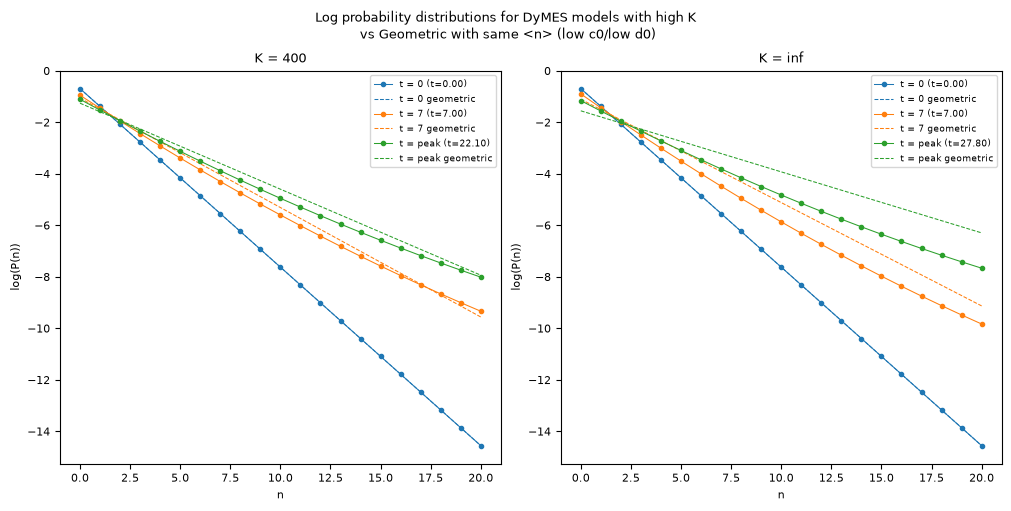

In [39]:
fig, axs = plt.subplots(1, 2, figsize = (10, 5), constrained_layout = True)
axs = axs.flatten()

for i in range(0, 2):
    dymes_model = model_list[i + 2]

    peak_index = np.argmax(dymes_model.states)
    peak_time = dymes_model.time[peak_index]

    snapshot_times = [
        (nearest_stored_time(dymes_model, 0), "t = 0"),
        (nearest_stored_time(dymes_model, 7), "t = 7"),
        (nearest_stored_time(dymes_model, peak_time), "t = peak"),
    ]

    for time_key, time_label in snapshot_times:
        n_vals, log_p_vals, n_mean = log_prob_curve(dymes_model, time_key, n_max = log_prob_n_max)
        line, = axs[i].plot(n_vals, log_p_vals, marker = 'o', markersize = 3, linewidth = 0.75,
                             label = f"{time_label} (t={time_key:.2f})")

        geo_n_vals, geo_log_p_vals = geometric_log_prob_curve(n_mean, n_max = log_prob_n_max)
        axs[i].plot(geo_n_vals, geo_log_p_vals, linestyle = '--', linewidth = 0.75,
                    color = line.get_color(), label = f"{time_label} geometric")

    axs[i].set_xlabel("n")
    axs[i].set_ylabel("log(P(n))")
    axs[i].set_title(labels[i + 2])
    axs[i].legend(fontsize = 'small')

fig.suptitle("Log probability distributions for DyMES models with high K\n vs Geometric with same <n> (low c0/low d0)")
save_fig(fig, 'fig_2c')
plt.show()

# SIR d*n*/d*t* vs DyMES <*f*> at t = 0 for K = inf

In [40]:
dn_dt_0 = (0.0033) * (99) * (1) - (1/6) * 1
dn_dt_0

0.16003333333333333

In [42]:
K_inf_params_at_start = {
    'm_0': 100,
    'G': 100,
    'd_0': 1/6,
    'c0': 0.0033, 
    'c1': 1,
    'c2': 1,
    'tau': 0.0001,
    '<n>_(t-tau)': 0,
    'm_(t-tau)': 100, # should be set to the same value as m_0
    'h': 1,
  }

Z = rf.R_mean(pandemic_func_K_inf, 100, 100, K_inf_params_at_start, K_inf.lambdas[0])
exp_n = rf.Rn_mean(pandemic_func_K_inf, 100, 100, K_inf_params_at_start, K_inf.lambdas[0])/Z
exp_n2 = rf.Rn2_mean(pandemic_func_K_inf, 100, 100, K_inf_params_at_start, K_inf.lambdas[0])/Z

dymes_exp_f =  0.0033 * (100) * exp_n - 0.0033 * 0.0001 * (1/6) * exp_n2 - 0.0033 * exp_n2 - (1/6) * exp_n
Z, exp_n, exp_n2, dymes_exp_f

(np.float64(2.0),
 np.float64(1.0000000000000002),
 np.float64(3.0000000000000004),
 np.float64(0.15343316833333337))